# Shared setup for causal tracing
Run on a Colab GPU. This loads the exact GPT-2 XL revision and precision used for the baseline. It does not rerun 200 edits.

The Python 3.11 model lives inside the subprocess below, not in Colab's Python 3.13 kernel. Add tracing code to the same `EXPERIMENT` block to reuse `model`, `tokenizer`, and `mt` in that process. A new execution reloads the model. This starter has not yet been run on a GPU.


In [1]:
import os, sys, subprocess, json, shutil
from pathlib import Path
os.environ['MPLBACKEND'] = 'Agg'
ROOT = Path('/content/nlp544')
if not ROOT.exists():
    subprocess.run(['git','clone','https://github.com/rohithreddy009/nlp544.git',str(ROOT)],check=True)

def stream(command):
    with subprocess.Popen(command,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1) as p:
        for line in p.stdout:
            print(line,end='',flush=True)
        if p.wait():
            raise RuntimeError('Command failed; see output above.')

stream([sys.executable,'-u',str(ROOT/'scripts/setup.py')])
PYTHON = str(ROOT/'.venv/bin/python')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 90.4 MB/s eta 0:00:00
Installed Python 3.11.17 in 1.02s
 + cpython-3.11.17-linux-x86_64-gnu (python3.11)
Using CPython 3.11.17
Creating virtual environment with seed packages at: nlp544/.venv
 + packaging==26.3
 + pip==26.2.1
 + setuptools==84.2.0
 + wheel==0.48.0
Activate with: source nlp544/.venv/bin/activate
Looking in indexes: https://download.pytorch.org/whl/cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.5/780.5 MB 29.6 MB/s  0:00:14
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 356.9 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 321.0 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 358.7 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 32.5 MB/s  0:00:12
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 67.4 MB/s  0:00:04
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 289.2 MB/s  0:00:00
     ━━━━━━

In [4]:
EXPERIMENT = r"""
import sys
import torch

sys.path.insert(0, '/content/nlp544/scripts')
from model_setup import load_model_and_tokenizer

# This also configures the ROME folder and Python import path.
model, tokenizer = load_model_and_tokenizer()

# Import ROME helpers after configuring that path.
from experiments.causal_trace import ModelAndTokenizer, predict_token

mt = ModelAndTokenizer(model=model, tokenizer=tokenizer)

examples = [
    ("The Eiffel Tower is located in the city of", "Paris"),
    ("The Space Needle is in downtown", "Seattle"),
    ("The capital of France is", "Paris"),
]

with torch.no_grad():
    for prompt, expected in examples:
        predictions, probabilities = predict_token(
            mt, [prompt], return_p=True
        )
        predicted = predictions[0].strip()

        print("Prompt:", prompt)
        print("Expected:", expected)
        print("Predicted next token:", repr(predicted))
        print("Probability:", round(probabilities[0].item(), 4))
        print("Matches:", predicted == expected)
        print()

print("PREDICTION CHECK COMPLETE")
"""

stream([PYTHON, '-u', '-c', EXPERIMENT])

/content/nlp544/.venv/lib/python3.11/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Prompt: The Eiffel Tower is located in the city of
Expected: Paris
Predicted next token: 'Paris'
Probability: 0.9341
Matches: True

Prompt: The Space Needle is in downtown
Expected: Seattle
Predicted next token: 'Seattle'
Probability: 0.9764
Matches: True

Prompt: The capital of France is
Expected: Paris
Predicted next token: 'the'
Probability: 0.1012
Matches: False

PREDICTION CHECK COMPLETE


/content/nlp544/.venv/lib/python3.11/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Noise scale: 0.13353188708424568
Starting MLP tracing. Please wait...
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font fami

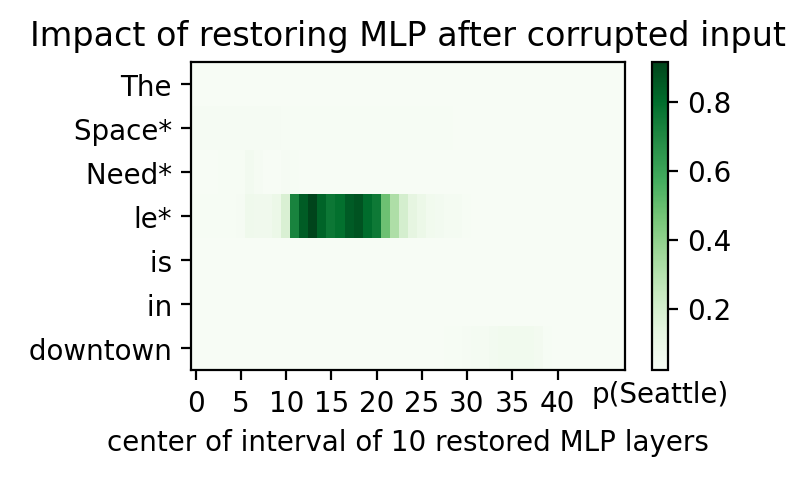

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
EXPERIMENT = r"""
import sys
import json
from pathlib import Path
import numpy as np
import torch

sys.path.insert(0, '/content/nlp544/scripts')
from model_setup import load_model_and_tokenizer

model, tokenizer = load_model_and_tokenizer()

from experiments.causal_trace import (
    ModelAndTokenizer,
    calculate_hidden_flow,
    collect_embedding_std,
    plot_trace_heatmap,
)

mt = ModelAndTokenizer(model=model, tokenizer=tokenizer)

# Save inside this Colab session.
out = Path('/content/causal_tracing/space_needle_demo_v1')
out.mkdir(parents=True, exist_ok=True)

prompt = "The Space Needle is in downtown"
subject = "Space Needle"
calibration_subjects = ["Space Needle", "Eiffel Tower", "France"]

with torch.no_grad():
    noise = 3 * collect_embedding_std(mt, calibration_subjects)

print("Noise scale:", noise, flush=True)
print("Starting MLP tracing. Please wait...", flush=True)

with torch.no_grad():
    result = calculate_hidden_flow(
        mt,
        prompt,
        subject,
        expect="Seattle",
        samples=10,
        noise=noise,
        kind="mlp",
        window=10,
    )

if not result.get("correct_prediction", False):
    raise RuntimeError("The model did not predict Seattle.")

scores = result["scores"].detach().cpu().numpy()

np.savez_compressed(
    out / "trace_scores.npz",
    scores=scores,
    input_tokens=np.array(result["input_tokens"]),
    subject_range=np.array(result["subject_range"]),
    clean_probability=float(result["high_score"]),
    corrupted_probability=float(result["low_score"]),
)

settings = {
    "prompt": prompt,
    "subject": subject,
    "answer": result["answer"],
    "model": "gpt2-xl",
    "precision": "float32",
    "samples": 10,
    "kind": "mlp",
    "window": 10,
    "noise": float(noise),
    "noise_calibration_subjects": calibration_subjects,
    "purpose": "Initial demonstration",
}
(out / "settings.json").write_text(json.dumps(settings, indent=2))

plot_trace_heatmap(
    result,
    savepdf=str(out / "space_needle_mlp.png"),
)

summary = {
    "clean_probability": float(result["high_score"]),
    "corrupted_probability": float(result["low_score"]),
    "highest_restored_probability": float(scores.max()),
}
(out / "summary.json").write_text(json.dumps(summary, indent=2))

print(json.dumps(summary, indent=2))
print("TRACE COMPLETE", flush=True)
"""

stream([PYTHON, '-u', '-c', EXPERIMENT])

# Show the heatmap.
from IPython.display import Image, display
display(Image(
    filename='/content/causal_tracing/space_needle_demo_v1/'
             'space_needle_mlp.png'
))

# Download all results together.
import shutil
from google.colab import files

archive = shutil.make_archive(
    '/content/Soham_SpaceNeedle_Trace',
    'zip',
    root_dir='/content/causal_tracing/space_needle_demo_v1',
)
files.download(archive)

/content/nlp544/.venv/lib/python3.11/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Noise scale: 0.13353188708424568
Starting Eiffel Tower MLP tracing...
{
  "clean_probability": 0.9340540766716003,
  "corrupted_probability": 0.006249030586332083,
  "highest_restored_probability": 0.497828871011734
}
TRACE COMPLETE


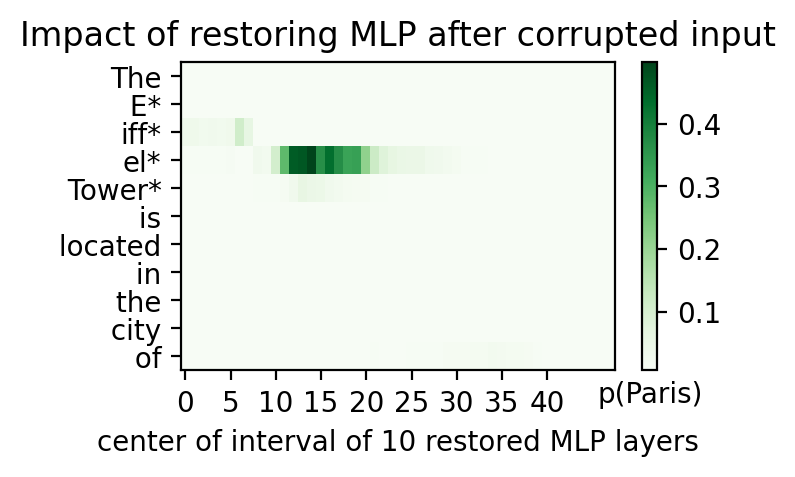

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
EXPERIMENT = r"""
import sys
import json
import logging
from pathlib import Path
import numpy as np
import torch

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

sys.path.insert(0, '/content/nlp544/scripts')
from model_setup import load_model_and_tokenizer

model, tokenizer = load_model_and_tokenizer()

from experiments.causal_trace import (
    ModelAndTokenizer,
    calculate_hidden_flow,
    collect_embedding_std,
    plot_trace_heatmap,
)

mt = ModelAndTokenizer(model=model, tokenizer=tokenizer)

out = Path('/content/causal_tracing/eiffel_tower_demo_v1')
out.mkdir(parents=True, exist_ok=True)

prompt = "The Eiffel Tower is located in the city of"
subject = "Eiffel Tower"

# Same calibration set and settings as the Space Needle experiment.
calibration_subjects = ["Space Needle", "Eiffel Tower", "France"]

with torch.no_grad():
    noise = 3 * collect_embedding_std(mt, calibration_subjects)

print("Noise scale:", noise, flush=True)
print("Starting Eiffel Tower MLP tracing...", flush=True)

with torch.no_grad():
    result = calculate_hidden_flow(
        mt,
        prompt,
        subject,
        expect="Paris",
        samples=10,
        noise=noise,
        kind="mlp",
        window=10,
    )

if not result.get("correct_prediction", False):
    raise RuntimeError("The model did not predict Paris.")

scores = result["scores"].detach().cpu().numpy()

np.savez_compressed(
    out / "trace_scores.npz",
    scores=scores,
    input_tokens=np.array(result["input_tokens"]),
    subject_range=np.array(result["subject_range"]),
    clean_probability=float(result["high_score"]),
    corrupted_probability=float(result["low_score"]),
)

settings = {
    "prompt": prompt,
    "subject": subject,
    "answer": result["answer"],
    "model": "gpt2-xl",
    "precision": "float32",
    "samples": 10,
    "kind": "mlp",
    "window": 10,
    "noise": float(noise),
    "noise_calibration_subjects": calibration_subjects,
    "purpose": "Initial demonstration",
}
(out / "settings.json").write_text(json.dumps(settings, indent=2))

plot_trace_heatmap(
    result,
    savepdf=str(out / "eiffel_tower_mlp.png"),
)

summary = {
    "clean_probability": float(result["high_score"]),
    "corrupted_probability": float(result["low_score"]),
    "highest_restored_probability": float(scores.max()),
}
(out / "summary.json").write_text(json.dumps(summary, indent=2))

print(json.dumps(summary, indent=2))
print("TRACE COMPLETE", flush=True)
"""

stream([PYTHON, '-u', '-c', EXPERIMENT])

from IPython.display import Image, display
display(Image(
    filename='/content/causal_tracing/eiffel_tower_demo_v1/'
             'eiffel_tower_mlp.png'
))

import shutil
from google.colab import files

archive = shutil.make_archive(
    '/content/Soham_EiffelTower_Trace',
    'zip',
    root_dir='/content/causal_tracing/eiffel_tower_demo_v1',
)
files.download(archive)

### Initial causal tracing results

I ran MLP causal tracing on two factual prompts using the original GPT-2 XL model. Each experiment used 10 noise samples, a 10-layer restoration window, and the same noise scale, estimated from three calibration subjects.

For the Space Needle prompt, the probability of “Seattle” fell from 97.64% to 2.25% after subject corruption. The strongest restoration increased it to 91.33%, at the final subject token, “le,” with the window centered at layer index 13.

For the Eiffel Tower prompt, the probability of “Paris” fell from 93.41% to 0.62%. The strongest restoration increased it to 49.78%, at “el,” within “Eiffel,” with the window centered at layer index 14.

These examples show that restoring selected MLP computations at subject-token positions can recover factual predictions. Recovery strength and the most influential token differed between examples. Because each intervention restores a window of layers, these plots do not identify one exact storage layer.